# 📘 11.1 Solving Parabolic Equations
###

This notebook focuses on the means of solving parabolic partial differential equations that have a time-like direction, from which a solution can be marched forward in time starting from an initial condition.

---

> By the end of this notebook, you should be able to:
>
> * **Understand** how parabolic partial differential equations (like the 1D diffusion equation) represent initial value problems that march forward in a time-like direction.
> * **Formulate** the Forward in Time, Centred in Space (FTCS) explicit finite difference scheme for solving diffusion problems.
> * **Perform** Von Neumann Stability Analysis to derive the amplification factor and determine stability limits ($|A(k)| \le 1$) for numerical schemes.
> * **Explain** the Lax-Equivalence Theorem and how consistency and stability guarantee the convergence of a numerical solution to the true physical solution.

## 📂 11.1.0 How to use this notebook

This notebook explains the means by which we can solve PDEs whose forms allow for the propagation of a solution in a single - time-like - direction. For this we will rely on the use of Finite Differences and the discretisation of the solution space, similar to the relaxation methods we used in the solution of boundary value ODEs in [Notebook 10.1](https://colab.research.google.com/drive/1cv1ZaIGgPqhnJGtExw1_kIRviBwcntgW?usp=sharing).

> ### 🧭 Theory Preface
> When dealing with parabolic equations such as the 1D diffusion equation, we treat time as a unidirectional coordinate. This means that a solution is uniquely determined by marching forward from an **initial condition** under the influence of physical constraints at the boundary edges.
>
> To successfully model these systems, this notebook takes you through the following essential steps:
> 1. **Discretisation:** How we approximate spatial derivatives using central finite differences, and temporal derivatives using forward-marching stencils (FTCS).
> 2. **Stability Analysis:** Using Von Neumann analysis to mathematically map the propagation of numeric perturbations and establish a rigorous maximum step size constraint ($|A(k)| \le 1$). *This is similar to the perturbation analyis, but updated to allow for spatial and temporal variation not seen in ODEs.
> 3. **Convergence Verification:** Invoking the Lax-Equivalence Theorem to guarantee that as our step sizes decrease ($\Delta x, \Delta t \to 0$), our numerical approximation converges directly to the exact analytical solution.
> 4. **Practical Implementation:** Working through a complete Python-based solver utilising NumPy and Matplotlib to visualise how heat or concentrations diffuse across a physical domain.

## 📂 11.1.1 Time Advancement Methods in PDEs

---

The numerical solution of PDEs is far more demanding than that of ODEs, and the diversity of PDE types precludes the availability of general-purpose computer programs for their solution. While commercial codes exist (such as Finite Element and CFD packages), these consist of libraries containing different methods and options where solvers change depending on transient or steady-state simulations. Consequently, the user must be fully aware of how these methods work to obtain consistent and meaningful results.

One of the main difficulties encountered in PDEs is their classification (as discussed in [Notebook 10.4](https://colab.research.google.com/drive/11JiYdOZ-_aohusjpzLgFDdaJ4Oju1hbG?usp=playground)). For instance, whether an equation is Elliptic, Parabolic, or Hyperbolic fundamentally changes how we must approach its solution. In the case of parabolic and hyperbolic equations, we are dealing with initial value or transient problems that evolve in a *time-like* direction. In most practical cases, this is a system that either evolves in time toward a steady state or fluctuates around a statistically stationary state (i.e., mean and root-mean-square fluctuations are constant, but the system experiences chaotic fluctuations—such as in a turbulent flow).

Consider the **diffusion equation** which arises in mechanical and aerospace engineering for problems of heat conduction:
$$\frac{\partial \phi}{\partial t} = D\nabla^2\phi,\qquad \nabla^2\phi = \frac{\partial^2 \phi}{\partial x^2} + \frac{\partial^2 \phi}{\partial y^2} + \frac{\partial^2 \phi}{\partial z^2},$$
where $D$ is a constant diffusion coefficient.

The solution to this equation is the field $\phi(t,x,y,z)$ which varies in space ($x,y,z$) and time. This equation is classified as **parabolic**. Unlike an *elliptic* PDE, we do not have boundary conditions that fully enclose the spatial-temporal solution domain. Instead, we specify boundary conditions at the edges of the physical spatial domain at $\min(x), \max(x)$, $\min(y), \max(y)$, and $\min(z), \max(z)$. Propagation occurs onward in time, meaning that if we know the initial condition $\phi(0,x,y,z)$, we have an explicit expression for $\partial \phi/\partial t$ at all points in the domain, which we can use to march our solution forward in time.

This time-marching process is represented in Figure 11.1 for a single spatial direction, indexed by $j$. If the $x$-domain is discretised into $N_x$ points, then $\min(x) \equiv j=0$ and $\max(x) \equiv j=N_x-1$. In order to evaluate the spatial derivatives, boundary conditions are needed at $j=0$ and $j=N_x-1$, similar to the boundary value ODEs in [Notebook 10.1](https://colab.research.google.com/drive/1cv1ZaIGgPqhnJGtExw1_kIRviBwcntgW?usp=playground).

The time domain is discretised into $N_t$ points from an initial time $t=t_0$ to a final time $t=T$. This final time may be specified explicitly or the simulation may run until the problem reaches a steady state. In this formulation, a superscript $n$ is used to denote the point in time to separate it from the spatial coordinate index, meaning any point in space and time is represented as:
$$\phi(t^n,x_j) = \phi^n_j.$$

<figure>
  <img src="https://drive.google.com/uc?id=1ttwmvN9P1lFnlcOYtmhLNIsQiuFt7l4q" alt="" style="width:100%;max-width:400px;background-color: white">
  <figcaption style="text-align: center; font-style: italic; margin-top: 5px;">
    Figure 11.1: Spatial boundary conditions and initial conditions for a forward time-marching solution to fill in a solution field in space and time — From (Hutchinson (2015), Cambridge University Press).
  </figcaption>
</figure>

The *initial condition* is supplied at $n=0$ for all $j$ values and then propagated forward in time.

To simplify this, let us consider a single spatial direction where the diffusion equation reduces to:

$$\frac{\partial \phi}{\partial t} = D\frac{\partial^2 \phi}{\partial x^2}.$$

The same process applies if we have multiple spatial dimensions. We would simply introduce an additional spatial index for each direction and include the discretisation of the corresponding spatial derivative terms.

The simplest way to discretise the solution domain is via a finite difference representation of the governing PDE. Starting with the spatial domain, we have a second derivative that we can approximate using a central difference:

$$\frac{\partial^2\phi^n_j}{\partial x^2} = \frac{\phi^n_{j-1}-2\phi^n_j + \phi^n_{j+1}}{\Delta x^2}+\mathcal{O}(\Delta x^2),\tag{11.1}$$

Because this is a partial derivative, the spatial gradient is a function of time, which is why we represent it in terms of the field in time and space at $\phi(t^n,x_j)$.

To advance our solution forward in time, we want a temporal discretisation in terms of $t^{n+1}$ and $t^{n}$, such as the forward difference:

$$\frac{\partial \phi^n_j}{\partial t} = \frac{\phi^{n+1}_j-\phi^n_j}{\Delta t}+\mathcal{O}(\Delta t).\tag{11.2}$$

Substituting equations (11.1) and (11.2) into the governing PDE yields:

$$\frac{\phi^{n+1}_j-\phi^n_j}{\Delta t}=D\frac{\phi^n_{j-1}-2\phi^n_j + \phi^n_{j+1}}{\Delta x^2},$$

which represents the discretised form of the diffusion equation that our numerical solution must satisfy at all internal points $(x_j,t^n)$ throughout the domain.

Since the time derivative uses a *forward stencil* in time and the spatial derivative uses a *centred stencil* in space, this approach is commonly referred to as the **Forward in Time, Centred in Space (FTCS)** scheme.

## 📂 11.1.2 Forward in Time, Centred in Space

---

As discussed in Section 11.1.1, using a forward difference in time and a centred difference in space leads to the discretised expression:

$$\frac{\phi^{n+1}_j-\phi^n_j}{\Delta t}=D\frac{\phi^n_{j-1}-2\phi^n_j + \phi^n_{j+1}}{\Delta x^2}.$$

The main advantage of this form becomes obvious when we rearrange it to solve for the future state:

$$\phi^{n+1}_j = \phi^n_j+\frac{D\Delta t}{\Delta x^2}\left(\phi^n_{j-1}-2\phi^n_j + \phi^n_{j+1} \right).$$

As we can see, this **Forward in Time, Centred in Space** expression is **explicit** in time; we can determine the updated value at step $n+1$ entirely based on the known values from time step $n$.

The **order of accuracy** of this method depends on the truncation error of the finite difference expressions used. In this case, the spatial derivative has an error of $\mathcal{O}(\Delta x^2)$ and the temporal derivative has an error of $\mathcal{O}(\Delta t)$. Thus, this method is *second-order accurate* in space but only *first-order accurate* in time. The overall accuracy of the scheme is limited by the least accurate term, meaning any simulation using this method is overall *first-order accurate* in time.

Of course, the absolute accuracy depends on the number of points across which the problem is discretised. Having more points in space ($N_x$) and time ($N_t$) translates to smaller values of $\Delta x$ and $\Delta t$, thereby reducing the *truncation error* (i.e., enabling the finite differences to better approximate the true physical gradients). However, as we saw with ODEs, increasing the number of points also increases the number of computations, which can accelerate the accumulation of *floating-point* or *round-off* errors.


**So, how many grid points should we choose, or conversely, what step sizes ($\Delta x$ and $\Delta t$) are appropriate?**

Just as we did with ODEs, we must balance truncation and round-off errors with numerical stability. This raises an important question:

**How do we evaluate the stability of a method that depends not only on $\phi^{n+1}$ and $\phi^n$, but also includes spatial variations like $\phi^n_j$ and $\phi^n_{j\pm 1}$?**

## 📂 11.1.3 Von Neumann Stability Analysis

---

In our previous investigation of ODE stability ([Notebook 9.1](https://colab.research.google.com/drive/1EEWyEXA6aLItM85ZsPW-bFMd3YheHBNw?usp=playground)), we introduced a perturbation to our solution:
$$ \tilde{\phi}^n_j = \phi^n_j+\delta_{\phi^n_j}.$$

We briefly looked at representing $\delta_{\phi^n_j}$ as a complex variable, but in practical examples, we relaxed this requirement since we could still arrive at an amplification factor:
$$A = \frac{\delta_{\phi^{n+1}_j}}{\delta_{\phi^n_j}}.$$

Fortunately, we can apply this general approach to PDEs, but we must return to using a complex perturbation. More specifically, we model our perturbation as a wave represented in complex notation:
$$\phi(t_n,x) = e^{ikx}=\cos(kx)+i\sin(kx),$$

which corresponds to a complex wave with an unknown wavenumber $k=\frac{2\pi}{\lambda}$, where $\lambda$ is the wavelength (spatial period of the wave). This represents the spatial propagation of a perturbation through our numerical method. By representing $\phi$ in this form, we can account for the influence of spatial gradients by substituting the discrete spatial position of any point $j$ using:

$$ x = j\cdot\Delta x,$$

such that:
$$\phi(t^n,x_j) = \phi^n_j = e^{ikj\Delta x}.$$

To determine the amplification factor of the **Forward in Time, Centred in Space** method:
$$\phi^{n+1}_j = \phi^n_j+\frac{D\Delta t}{\Delta x^2}\left(\phi^n_{j-1}-2\phi^n_j + \phi^n_{j+1}
\right),$$

we substitute the perturbation $e^{ikj\Delta x}$ to obtain:

$$\phi^{n+1}_j = e^{ikj\Delta x} + \frac{D\Delta t}{\Delta x^2}\left(
  e^{ik(j-1)\Delta x} - 2e^{ikj\Delta x} + e^{ik(j+1)\Delta x}
   \right).$$

Factoring out $e^{ikj\Delta x}$ as a common term, we get:

$$\phi^{n+1}_j = \left[1 + \frac{D\Delta t}{\Delta x^2}\left(
  e^{-ik\Delta x} - 2 + e^{ik\Delta x}
   \right) \right]e^{ikj\Delta x}.$$

By Euler's formula and basic trigonometric identities:

$$e^{-ik\Delta x} + e^{ik\Delta x} = \cos(-k\Delta x) + i\sin(-k\Delta x) + \cos(k\Delta x) + i\sin(k\Delta x),$$

and because $\cos(-x) = \cos(x)$ and $\sin(-x) = -\sin(x)$, this simplifies to:

$$e^{-ik\Delta x} + e^{ik\Delta x} = 2\cos(k\Delta x).$$

Hence:

$$\phi^{n+1}_j = \left[1 + 2\frac{D\Delta t}{\Delta x^2}\left(
  \cos(k\Delta x) - 1
   \right)
\right]e^{ikj\Delta x}.$$

We can express this relation as:
$$\phi^{n+1}_j = A(k)\cdot e^{ikj\Delta x}, \qquad A(k) = 1 + 2\frac{D\Delta t}{\Delta x^2}\left(
  \cos(k\Delta x) - 1
   \right),$$

where $A(k)$ is the amplification factor expressed as a function of the spatial wavenumber of the perturbation.

>*Note:* Using the trigonometric identity $1-\cos(x) = 2\sin^2(x/2)$, you will also often see this amplification factor expressed as:
> $$ A(k) = 1 - 4\frac{D\Delta t}{\Delta x^2}\sin^2\left(\frac{k\Delta x}{2}\right)$$

For the method to be **stable**, we require that the perturbation does not grow over time:
$$|A(k)| \le 1 \quad \mbox{for all } k.$$

Let's analyse $A(k)$, noting how its behaviour depends directly on the term $\cos(k\Delta x)-1$.

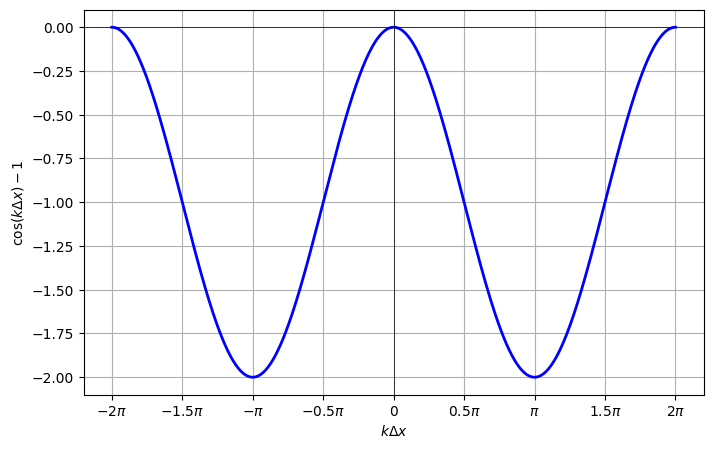

In [ ]:
# @title ####Plot $\cos(k\Delta x)-1$
import numpy as np
import matplotlib.pyplot as plt

# Generate x values from -2*pi to 2*pi
x = np.linspace(-2 * np.pi, 2 * np.pi, 1000)
y = np.cos(x) - 1

# Plot the function
plt.figure(figsize=(8, 5))
plt.plot(x, y, color='blue', linewidth=2)
plt.xlabel(r'$k\Delta x$')
plt.ylabel(r'$\cos(k\Delta x)-1$')

# Set x-ticks and labels in terms of pi
ticks = [-2 * np.pi, -1.5 * np.pi, -np.pi, -0.5 * np.pi, 0, 0.5 * np.pi, np.pi, 1.5 * np.pi, 2 * np.pi]
labels = [r'$-2\pi$', r'$-1.5\pi$', r'$-\pi$', r'$-0.5\pi$', r'$0$', r'$0.5\pi$', r'$\pi$', r'$1.5\pi$', r'$2\pi$']
plt.xticks(ticks, labels)

plt.grid(True)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.show()

Given that we must consider the full range of potential wavenumbers $k$, stability will be limited by the worst-case scenario. This occurs when the amplitude of $\cos(k\Delta x)-1$ is at its maximum negative value, which happens at $k\Delta x = \pi$, where $\cos(k\Delta x)-1=-2$:

$$A(k) = 1-4\frac{D\Delta t}{\Delta x^2}.$$

For the method to remain stable, we require:

$$\left|1-4\frac{D\Delta t}{\Delta x^2}\right| \le 1,$$

which corresponds to the compound inequality:
$$-1 \le 1-4\frac{D\Delta t}{\Delta x^2} \le 1.$$

Evaluating the left-hand inequality:
$$-2 \le -4\frac{D\Delta t}{\Delta x^2},$$

which simplifies to (recalling that multiplying or dividing by a negative number reverses the inequality sign):
$$\frac{1}{2} \ge \frac{D\Delta t}{\Delta x^2}.$$

Evaluating the right-hand inequality:
$$-4\frac{D\Delta t}{\Delta x^2} \le 0,$$

which simplifies to:
$$ \frac{D\Delta t}{\Delta x^2} \ge 0.$$

Combining these conditions yields the stable range:

$$ 0 \le \frac{D\Delta t}{\Delta x^2} \le \frac{1}{2}.$$

Assuming that physical and numerical constants are positive ($D>0$, $\Delta t>0$, $\Delta x>0$), the practical limit becomes:

$$\frac{D\Delta t}{\Delta x^2} \le \frac{1}{2}.$$

This means that the **Forward in Time, Centred in Space** method is **conditionally stable**, with the allowable time step strictly constrained by the chosen spatial grid spacing:

$$\Delta t \le \frac{\Delta x^2}{2D}.$$

## 📂 11.1.4 Convergence and Lax-Equivalence Theorem

---

Let's assume we have configured our FTCS solver and discretised our spatial domain, choosing a stable time step such that $\Delta t \le \Delta x^2/2D$.

**Will our numerical solution converge toward the true analytical solution?**

By using Taylor series expansions to derive our finite difference expressions, we have ensured that our discretised equations are mathematically **consistent** with the original continuous PDE, up to the limits of the *truncation error*.

Through Von Neumann Stability Analysis, we can guarantee that our numerical solution will not grow unboundedly. However, we must still prove that the overall method converges.

Mathematically, **convergence** is defined as:
$$\lim_{\Delta x \to 0, \Delta t \to 0} \left( \phi^n_j - \phi(t^n,x_j) \right) = 0.$$

That is, as the grid spacing and time step approach zero, our numerical approximation must approach the exact solution.

> ### 📖 Definition
> **Lax-Equivalence Theorem:** This theorem states that for a well-posed linear initial value problem, a linear finite difference method is *convergent* if and only if it is both *consistent* and *stable*.

Any finite difference method is *consistent* as long as its truncation error, $\epsilon_{\text{trunc}}$, vanishes as the grid spacing approaches zero:
$$\lim_{h \to 0} \frac{\epsilon_{\text{trunc}}}{h} = 0.$$

By formulating our finite difference equations using Taylor series expansions, this consistency is naturally assured. For example, in the forward temporal difference:
$$\frac{\partial \phi^n_j}{\partial t} = \frac{\phi^{n+1}_j-\phi^n_j}{\Delta t}+\mathcal{O}(\Delta t),$$

the truncation error is $\epsilon_{\text{trunc}} = C\Delta t$, where $C$ is a constant. Thus, as $\Delta t \to 0$, $\epsilon_{\text{trunc}} \to 0$.

According to the **Lax-Equivalence Theorem**, as long as we use consistent finite difference approximations and satisfy the stability conditions, our numerical solution is guaranteed to converge toward the exact physical solution as we refine our grid spacing.

## 📂 11.1.5 Numerical Example of Forward in Time, Centred in Space Solution

To demonstrate the practical application of the **Forward in Time, Centred in Space (FTCS)** scheme, we solve the 1D diffusion equation:
$$\frac{\partial \phi}{\partial t} = D\frac{\partial^2 \phi}{\partial x^2}$$
over a spatial domain of length $L = 1.0$ with a diffusion coefficient $D = 0.1$. The physical domain is discretised using $N_x = 50$ evenly spaced points. We impose fixed **Dirichlet boundary conditions** (More on that in Notebook 11.2) at both ends, setting $\phi(t, 0) = 0$ and $\phi(t, L) = 0$.

To ensure numerical stability of this explicit time-marching scheme, we must satisfy the stability criterion derived from the Von Neumann stability analysis:
$$\Delta t \le \frac{\Delta x^2}{2D}$$
In this simulation, we select a stable time step with a safety factor by setting $\Delta t = 0.4 \frac{\Delta x^2}{D}$. This guarantees that high-frequency numerical perturbations decay rather than grow exponentially.

### Simulation Setup & Expected Behaviour
We initialise the field $\phi$ with a sharp **Gaussian pulse** centred at $x = 0.5$:
$$\phi(0, x) = e^{-100(x - 0.5)^2}$$
As the simulation advances through $300$ discrete time steps, the solver iteratively computes the updated field values at each internal grid point. Due to the nature of physical diffusion, you will observe the sharp initial pulse spread outward, flatten, and decrease in amplitude over time as it flows toward the zero-value boundaries, illustrating how gradients naturally smooth out over time.

---

Spatial step (dx): 0.01010
Stable time step (dt): 0.00041 (using 0.4 * dx^2 / D)
Number of time steps: 1225


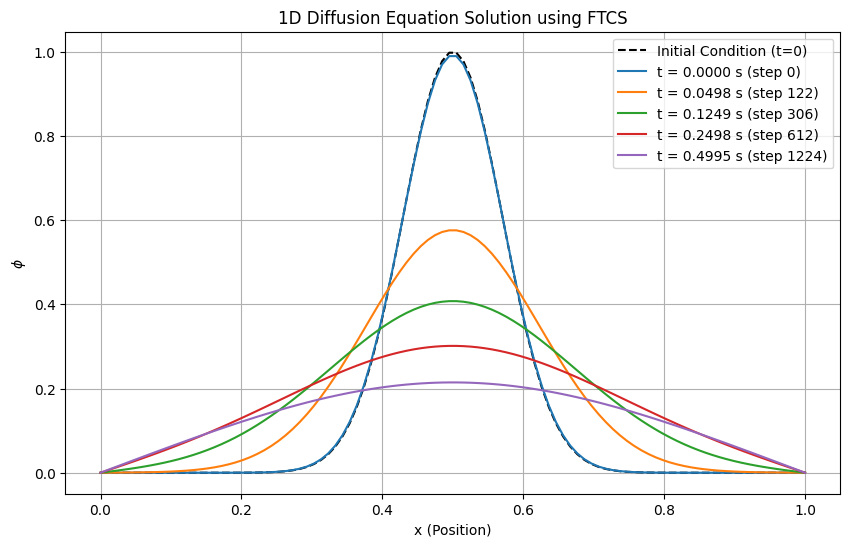

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Physical and Numerical Parameters ---
L = 1.0          # Length of the spatial domain
D = 0.1          # Diffusion coefficient
T_max = 0.5      # Maximum simulation time

Nx = 100          # Number of spatial grid points
dx = L / (Nx - 1)
x = np.linspace(0, L, Nx)

# Stability criterion for FTCS: dt <= dx^2 / (2 * D)
# We choose a stable time step with a safety factor
dt = 0.4 * (dx**2) / D
Nt = int(T_max / dt)

# larger time step
#dt = 0.54 * (dx**2) / D
#Nt = int(T_max / dt)

print(f"Spatial step (dx): {dx:.5f}")
print(f"Stable time step (dt): {dt:.5f} (using 0.4 * dx^2 / D)")
print(f"Number of time steps: {Nt}")

# --- Initial Condition ---
# Let's use a Gaussian pulse centered in the middle of the domain
phi = np.exp(-100 * (x - 0.5)**2)

# Keep a copy of the initial state for plotting
phi_initial = phi.copy()

# --- Boundary Conditions (Dirichlet) ---
phi_left = 0.0
phi_right = 0.0

# --- Time-stepping Loop (FTCS Solver) ---
# We preallocate phi_next to store the next state
phi_next = phi.copy()

# Save some profiles at intermediate times to plot the evolution
plot_steps = [0, int(Nt*0.1), int(Nt*0.25), int(Nt*0.5), Nt-1]
saved_profiles = {}

for n in range(Nt):
    # Apply FTCS formula to internal nodes only (1 to Nx-2)
    # note we don't solve at boundary points
    for j in range(1, Nx - 1):
        phi_next[j] = phi[j] + (D * dt / dx**2) * (phi[j-1] - 2*phi[j] + phi[j+1])

    # Enforce Boundary Conditions
    phi_next[0] = phi_left
    phi_next[-1] = phi_right

    # Update state for the next step
    phi = phi_next.copy()

    if n in plot_steps:
        saved_profiles[n] = phi.copy()

# --- Plotting the Results ---
plt.figure(figsize=(10, 6))
plt.plot(x, phi_initial, 'k--', label='Initial Condition (t=0)')
for step, profile in saved_profiles.items():
    t_current = step * dt
    plt.plot(x, profile, label=f't = {t_current:.4f} s (step {step})')

plt.title('1D Diffusion Equation Solution using FTCS')
plt.xlabel('x (Position)')
plt.ylabel(r'$\phi$')
plt.grid(True)
plt.legend()
plt.show()

Try reducing the number of time-steps and see what happens!

## 📂 Bridge to Notebook 11.2

In this notebook, we explored the foundational elements of solving parabolic partial differential equations. By implementing the explicit **Forward in Time, Centred in Space (FTCS)** scheme, we observed how spatial diffusion smooths out concentration gradients starting from an initial condition.

However, to keep our initial solver straightforward, we relied on simple, fixed zero-value boundaries (Dirichlet conditions) at both ends of the domain. In real-world engineering and physics problems, boundary conditions are rarely this simple. We often encounter insulated ends (zero heat flux), constant heat inputs, or convective interfaces.

**Notebook 11.2** will build directly on this foundation by exploring different types of boundary conditions—including **Dirichlet**, **Neumann**, **Robin**, and **Periodic** conditions—and demonstrating how they can be mathematically discretised and robustly integrated into our finite difference solutions.

# 🤖 AI Acknowledgment

Google Gemini was used to proofread this notebook and provided the Python code for the Numerical Example in section 11.1.5.